In [1]:
import numpy as np

In [2]:
import pandas as pd 

patients = pd.read_csv("patients.csv")
diagnoses = pd.read_csv("diagnoses.csv")
outcomes = pd.read_csv("outcomes.csv")
labs = pd.read_csv("labs.csv")


In [3]:
patients = patients.merge(diagnoses, on='DiagnosisID')
patients = patients.merge(outcomes, on='OutcomeID')

In [4]:
patients['AdmissionDate'] = pd.to_datetime(patients['AdmissionDate'])
patients['DischargeDate'] = pd.to_datetime(patients['DischargeDate']) 
patients['LengthOfStay'] = (patients['DischargeDate'] - patients['AdmissionDate']).dt.days

In [5]:
print(patients.head())

   PatientID              Name  Age Gender  DiagnosisID AdmissionDate  \
0          1   Jorge Alexander   74      M           10    2025-04-25   
1          2       Rachel Bell   50      M            6    2025-05-01   
2          3       James Hayes   84      M            7    2025-04-23   
3          4          Cody Roy   85      M            6    2025-04-17   
4          5  Heather Robinson   56      F           10    2025-07-03   

  DischargeDate  OutcomeID  TreatmentCost DiagnosisName_x OutcomeName_x  \
0    2025-05-04          3           6435   Liver Disease      Deceased   
1    2025-05-12          1           4541            COPD     Recovered   
2    2025-05-06          2           7834          Cancer   Complicated   
3    2025-04-29          1           7155            COPD     Recovered   
4    2025-07-16          2           5077   Liver Disease   Complicated   

   Length of stay Abnormal Blood Sugar Flag Risk Score DiagnosisName_y  \
0               9                   

In [6]:
patients['OutcomeEncoded'] = patients['OutcomeName_y'].map({'Recovered':0, 'Complicated':1, 'Deceased':1}) 

In [7]:
patients["High Risk"] = np.where((patients['Age'] > 65) | (patients['OutcomeName_y'].isin(['Complicated', 'Deceased'])), 1, 0)


In [8]:
abnormal_conditions ={
    'Blood Sugar' : lambda x: x > 120,
    'Cholestrol' : lambda x: x > 200,
    'Hemoglobin' : lambda x: x < 13
}

def count_abnormal_labs(patient_id):
    patient_labs = labs[labs['PatientID'] == patient_id]
    count = 0
    for test_name, condition in abnormal_conditions.items():
        test_results = patient_labs[patient_labs['TestName'] == test_name]
        count += test_results['Result'].apply(condition).sum()
    return count

patients['AbnormalLabCount'] = patients['PatientID'].apply(count_abnormal_labs)     

            

In [9]:
features = patients[['Age', 'LengthOfStay', 'TreatmentCost','AbnormalLabCount']]
target = patients['OutcomeEncoded']

In [10]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.3, random_state=42)

In [11]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=500)
model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",500
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in

In [12]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred = model.predict(X_test)

print("Classification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.80      0.81        44
           1       0.50      0.56      0.53        16

    accuracy                           0.73        60
   macro avg       0.67      0.68      0.67        60
weighted avg       0.74      0.73      0.74        60

Confusion Matrix:
[[35  9]
 [ 7  9]]


In [13]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

y_pred = model.predict(X_test)
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1-score :", f1_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy : 0.7333333333333333
Precision: 0.5
Recall   : 0.5625
F1-score : 0.5294117647058824
[[35  9]
 [ 7  9]]
              precision    recall  f1-score   support

           0       0.83      0.80      0.81        44
           1       0.50      0.56      0.53        16

    accuracy                           0.73        60
   macro avg       0.67      0.68      0.67        60
weighted avg       0.74      0.73      0.74        60



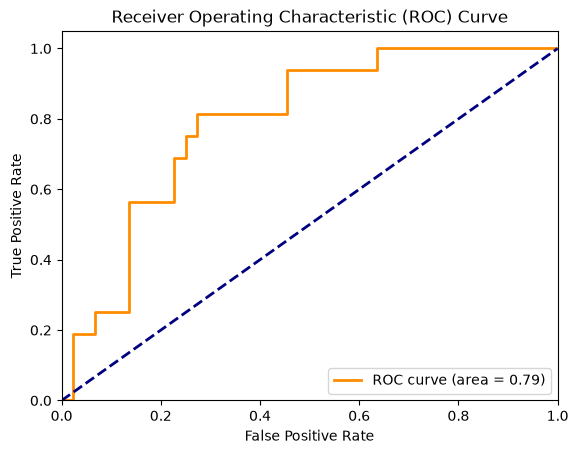

In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

y_prob = model.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='darkorange',lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

In [15]:
import joblib
joblib.dump(model, 'Risk_model1.ipynb')

['Risk_model1.ipynb']

In [16]:
import joblib

joblib.dump(model, "Risk_model1.joblib")

['Risk_model1.joblib']